# Read a session of DANDI:001528

[DANDI:001528](https://dandiarchive.org/dandiset/001528/draft) holds the fiber photometry recordings of Hadjas et al. (2025), [*Parkinson's disease-vulnerable and -resilient dopamine neurons display opposite responses to excitatory input*](https://www.biorxiv.org/content/10.1101/2025.06.03.657460v1). Each NWB file is one session of one mouse: the fluorescence of a calcium or dopamine sensor recorded through one fiber, while the axon terminals in the substantia nigra of ChrimsonR-expressing neurons of the subthalamic nucleus (STN) or the pedunculopontine nucleus (PPN) are stimulated with trains of 635 nm light.

This notebook streams one session and plots its signals and stimulation trains.

In [1]:
%matplotlib inline
import h5py
import matplotlib.pyplot as plt
import numpy as np
import remfile
from dandi.dandiapi import DandiAPIClient
from matplotlib.patches import Patch
from pynwb import NWBHDF5IO

## Open a session

`remfile` reads only the parts of the file that are used, and keeps them in a disk cache. The session below records SNr GABA neurons (GCaMP6f) while PPN inputs are stimulated at 40 Hz with trains of 250 ms, 1 s and 4 s.

In [ ]:
DANDISET_ID = "001528"
DANDISET_VERSION = "draft"


def open_session(asset_path):
    """Open an NWB file of the dandiset, streamed from the DANDI Archive."""
    with DandiAPIClient() as client:
        asset = client.get_dandiset(DANDISET_ID, DANDISET_VERSION).get_asset_by_path(asset_path)
        url = asset.get_content_url(follow_redirects=1, strip_query=True)
    file = remfile.File(url, disk_cache=remfile.DiskCache("remfile_cache"))
    return NWBHDF5IO(file=h5py.File(file, "r"), load_namespaces=True)

In [3]:
io = open_session("sub-C4561/sub-C4561_ses-varying-durations.nwb")
nwbfile = io.read()

print(f"Subject {nwbfile.subject.subject_id}, {nwbfile.subject.genotype}, sex {nwbfile.subject.sex}")
print(nwbfile.session_description)

Subject C4561, VGLUT2-Cre x VGAT-Flp, sex F
The mouse is placed in a plastic tub and receives 40 Hz optogenetic stimulation trains of 250 ms, 1 s and 4 s, in this order, repeated 5 times, with 10 s between the end of one train and the start of the next. The optogenetic epochs table lists every train.


## What the file holds

The raw photodetector signal is in `acquisition`, the signals computed from it in the `ophys` processing module, and the stimulation trains in `intervals`. Series names end with the recording site.

In [4]:
for name, series in nwbfile.acquisition.items():
    print(f"acquisition/{name}: {series.data.shape[0]} samples at {series.rate:.1f} Hz, {series.unit}")
for name, series in nwbfile.processing["ophys"].data_interfaces.items():
    rate = series.rate or 1 / np.median(np.diff(series.timestamps[:1000]))
    print(f"processing/ophys/{name}: {series.data.shape[0]} samples at {rate:.1f} Hz, {series.unit}")
for name in nwbfile.intervals:
    print(f"intervals/{name}: {len(nwbfile.intervals[name])} rows")

acquisition/raw_signal_SNr: 1580544 samples at 6103.5 Hz, a.u.
processing/ophys/deltaF_over_F_SNr: 25895 samples at 100.0 Hz, percent
processing/ophys/demodulated_calcium_signal_SNr: 1580544 samples at 6103.5 Hz, a.u.
processing/ophys/demodulated_isosbestic_control_SNr: 1580544 samples at 6103.5 Hz, a.u.
processing/ophys/downsampled_calcium_signal_SNr: 25895 samples at 100.0 Hz, a.u.
processing/ophys/downsampled_isosbestic_control_SNr: 25895 samples at 100.0 Hz, a.u.
intervals/optogenetic_epochs_table: 15 rows


## The session at a glance

dF/F over the whole session, with the stimulation trains shaded by duration.

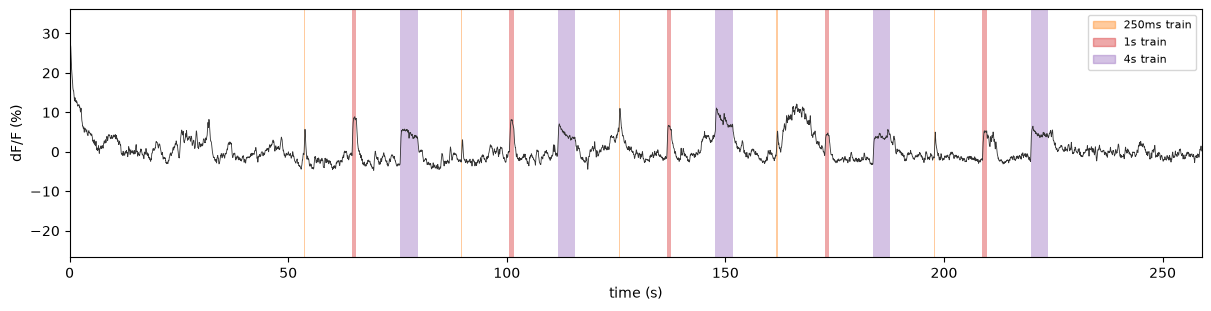

In [5]:
ophys = nwbfile.processing["ophys"]
dff = ophys["deltaF_over_F_SNr"]
dff_values, dff_times = dff.data[:], dff.get_timestamps()
trains = nwbfile.intervals["optogenetic_epochs_table"].to_dataframe()

duration_colors = {"250ms": "tab:orange", "1s": "tab:red", "4s": "tab:purple"}
figure, ax = plt.subplots(figsize=(12, 3), layout="constrained")
ax.plot(dff_times, dff_values, color="0.2", lw=0.6)
for train in trains.itertuples():
    ax.axvspan(train.start_time, train.stop_time, color=duration_colors[train.train_duration], alpha=0.4, lw=0)
ax.set(xlabel="time (s)", ylabel="dF/F (%)", xlim=(dff_times[0], dff_times[-1]))
ax.legend(
    [Patch(color=color, alpha=0.4) for color in duration_colors.values()],
    [f"{duration} train" for duration in duration_colors],
    loc="upper right",
    fontsize=8,
);

## From the raw signal to dF/F

The two LEDs (465 nm for the sensor, 405 or 415 nm for the isosbestic control) are switched on and off at two frequencies, so the raw photodetector signal carries both. Demodulating it at each frequency gives the sensor and isosbestic signals at the raw rate (`demodulated_*` series), which are then resampled to 100 Hz (`downsampled_*` series). dF/F is the sensor signal relative to a baseline fitted on the isosbestic signal. The series descriptions give the details.

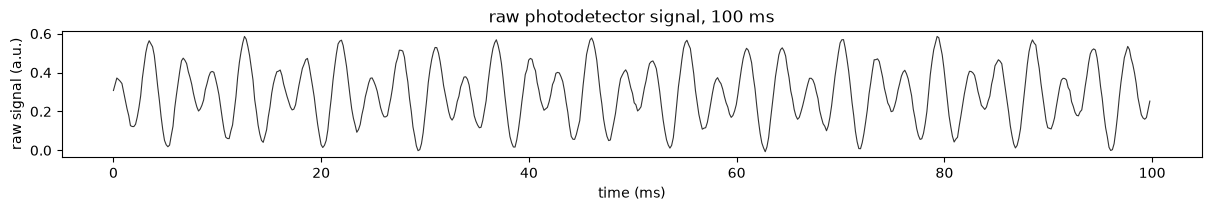

In [6]:
raw = nwbfile.acquisition["raw_signal_SNr"]
start = int(60 * raw.rate)  # 100 ms of raw signal, one minute into the session
raw_window = raw.data[start : start + int(0.1 * raw.rate)]

figure, ax = plt.subplots(figsize=(12, 2), layout="constrained")
ax.plot(1000 * np.arange(len(raw_window)) / raw.rate, raw_window, color="0.2", lw=0.8)
ax.set(xlabel="time (ms)", ylabel=f"raw signal ({raw.unit})", title="raw photodetector signal, 100 ms");

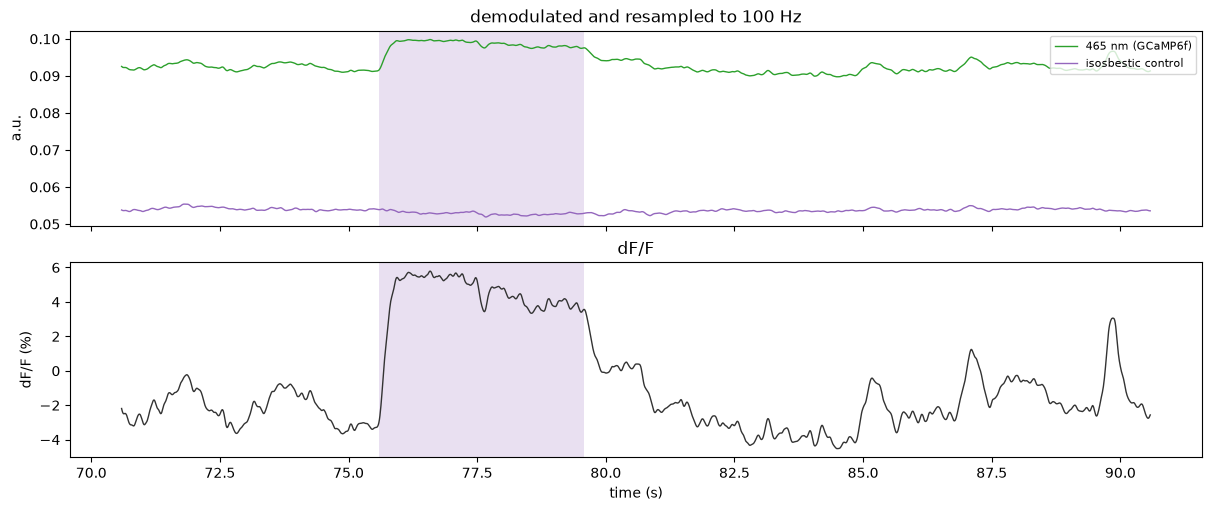

In [7]:
first_long_train = trains[trains["train_duration"] == "4s"].iloc[0]
window = (first_long_train.start_time - 5, first_long_train.start_time + 15)


def in_window(series):
    times = series.get_timestamps()
    first, last = np.searchsorted(times, window)
    return times[first:last], series.data[first:last]


figure, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True, layout="constrained")
axes[0].plot(*in_window(ophys["downsampled_calcium_signal_SNr"]), color="tab:green", lw=1, label="465 nm (GCaMP6f)")
axes[0].plot(
    *in_window(ophys["downsampled_isosbestic_control_SNr"]), color="tab:purple", lw=1, label="isosbestic control"
)
axes[0].set(title="demodulated and resampled to 100 Hz", ylabel="a.u.")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].plot(*in_window(dff), color="0.2", lw=1)
axes[1].set(title="dF/F", ylabel="dF/F (%)", xlabel="time (s)")
for ax in axes:
    ax.axvspan(first_long_train.start_time, first_long_train.stop_time, color=duration_colors["4s"], alpha=0.2, lw=0)

## Stimulation trains

The optogenetic epochs table has one row per train, with its onset and offset recorded by the acquisition system, the pulse frequency and the train duration of the protocol. Each train is delivered through the fiber of a stimulation site, which gives the stimulated input.

In [8]:
trains[["start_time", "stop_time", "stimulus_frequency", "train_duration", "power_in_mW", "wavelength_in_nm"]].head()

,start_time,stop_time,stimulus_frequency,train_duration,power_in_mW,wavelength_in_nm
id,,,,,,
0,53.586002,53.835694,40.0,250ms,5.0,635.0
1,64.586711,65.585480,40.0,1s,5.0,635.0
2,75.585946,79.585772,40.0,4s,5.0,635.0
3,89.586401,89.835274,40.0,250ms,5.0,635.0
4,100.585964,101.584896,40.0,1s,5.0,635.0


In [9]:
stimulation_sites = nwbfile.lab_meta_data["optogenetic_experiment_metadata"].optogenetic_sites_table
for effector in stimulation_sites["effector"][:]:
    print(f"{effector.name}: {effector.description}")

chrimsonR_PPN: ChrimsonR opsin used for optogenetic stimulation injected into the PPN.


## Recording site

The fiber photometry table has one row per fiber and excitation wavelength. Each series points to its row, which links the indicator, the fiber and its implant coordinates, and the optical devices.

In [10]:
fiber_photometry_table = nwbfile.lab_meta_data["fiber_photometry"].fiber_photometry_table.to_dataframe()
fiber_photometry_table["indicator"] = fiber_photometry_table["indicator"].map(lambda indicator: indicator.label)
fiber_photometry_table["optical_fiber"] = fiber_photometry_table["optical_fiber"].map(lambda fiber: fiber.name)
fiber_photometry_table[
    ["location", "indicator", "excitation_wavelength_in_nm", "emission_wavelength_in_nm", "optical_fiber"]
]

,location,indicator,excitation_wavelength_in_nm,emission_wavelength_in_nm,optical_fiber
id,,,,,
0,substantia nigra pars reticulata (SNr),GCaMP6f,465.0,515.0,optical_fiber_SNr
1,substantia nigra pars reticulata (SNr),GCaMP6f,405.0,515.0,optical_fiber_SNr


## Ontology terms (HERD)

NWB files can link metadata values to terms of external ontologies with HERD (HDMF External Resources Data), stored in the file under `/general/external_resources`. A free-text value such as `"substantia nigra pars reticulata (SNr)"` is resolved to an unambiguous term, so DANDI and other tools can tell which species or brain region a file is about without parsing the text.

NeuroConv writes these references during the conversion, from the terms listed in `external_resources_metadata.yaml` of the conversion code; no term is inferred. In this dataset:

- Subject species (`Mus musculus`): [NCBI Taxonomy](https://bioregistry.io/registry/ncbitaxon).
- Subject strain (`C57BL/6J`): [RRID](https://bioregistry.io/registry/rrid) of the Jackson Laboratory background strain.
- Brain regions (the `location` of the virus injections and of the fiber photometry table, e.g. SNr, SNc, STN, PPN, DLS, TS): the [Allen Mouse Brain Atlas](https://bioregistry.io/registry/mba) and [UBERON](https://bioregistry.io/registry/uberon), a cross-species anatomy ontology.
- Experimenters: [ORCID](https://bioregistry.io/registry/orcid).
- Institution: [ROR](https://bioregistry.io/registry/ror).

The genotype of the mouse lines is not annotated.

`nwbfile.external_resources` is a `HERD` object; `.to_dataframe()` gives one row per reference. The table below shows where each annotated value is in the file, the value (`key`) and its term.

In [11]:
from IPython.display import HTML, display


def annotated_field(object_id, relative_path):
    """Path in the file of an annotated value, for example subject/species."""
    names = []
    container = nwbfile.objects[object_id]
    while container.parent is not None:  # up to the NWBFile
        names.insert(0, container.name)
        container = container.parent
    return "/".join(name for name in [*names, relative_path] if name)


herd = nwbfile.external_resources.to_dataframe()
herd["annotated_value"] = [
    annotated_field(object_id, relative_path)
    for object_id, relative_path in zip(herd["object_id"], herd["relative_path"])
]
herd_table = herd[["annotated_value", "key", "entity_id", "entity_uri"]].copy()
# Make each term a link to its page
herd_table["entity_uri"] = herd_table["entity_uri"].map(lambda uri: f'<a href="{uri}" target="_blank">{uri}</a>')
display(HTML(herd_table.to_html(escape=False, index=False)))

annotated_value,key,entity_id,entity_uri
subject/species,Mus musculus,NCBITaxon:10090,http://purl.obolibrary.org/obo/NCBITaxon_10090
subject/strain,C57BL/6J,RRID:IMSR_JAX:000664,https://scicrunch.org/resolver/RRID:IMSR_JAX:000664
optogenetic_experiment_metadata/optogenetic_virus_injections/viral_vector_injection_PPN/location,pedunculopontine nucleus (PPN),MBA:1052,https://purl.brain-bican.org/ontology/mbao/MBA_1052
optogenetic_experiment_metadata/optogenetic_virus_injections/viral_vector_injection_PPN/location,pedunculopontine nucleus (PPN),UBERON:0002142,http://purl.obolibrary.org/obo/UBERON_0002142
fiber_photometry/fiber_photometry_virus_injections/viral_vector_injection_SNr/location,substantia nigra pars reticulata (SNr),MBA:381,https://purl.brain-bican.org/ontology/mbao/MBA_381
fiber_photometry/fiber_photometry_virus_injections/viral_vector_injection_SNr/location,substantia nigra pars reticulata (SNr),UBERON:0001966,http://purl.obolibrary.org/obo/UBERON_0001966
fiber_photometry/fiber_photometry_table/location,substantia nigra pars reticulata (SNr),MBA:381,https://purl.brain-bican.org/ontology/mbao/MBA_381
fiber_photometry/fiber_photometry_table/location,substantia nigra pars reticulata (SNr),UBERON:0001966,http://purl.obolibrary.org/obo/UBERON_0001966
general/experimenter,"Hadjas, Lotfi",orcid:0000-0003-1605-3601,https://orcid.org/0000-0003-1605-3601
general/experimenter,"Hollon, Nick",orcid:0000-0003-4827-1582,https://orcid.org/0000-0003-4827-1582


### Referenced ontologies

Each `entity_id` is a CURIE (`PREFIX:local_id`), e.g. `NCBITaxon:10090` or `UBERON:0001966`. The prefix names the ontology the term comes from. The cell below lists the prefixes of this file, each with a link to its page on [Bioregistry](https://bioregistry.io/), a registry of ontologies and identifier systems.

In [12]:
ONTOLOGIES = {
    "NCBITaxon": ("NCBI Taxonomy", "taxonomic identifiers of species"),
    "RRID": ("Research Resource Identifiers", "identifiers of research resources, e.g. mouse strains"),
    "MBA": ("Allen Mouse Brain Atlas", "structure ontology of the mouse brain"),
    "UBERON": ("Uberon", "cross-species anatomy ontology"),
    "orcid": ("ORCID", "identifiers of researchers"),
    "ror": ("Research Organization Registry", "identifiers of research institutions"),
}

items = []
for prefix in sorted({entity_id.split(":")[0] for entity_id in herd["entity_id"]}, key=str.lower):
    name, description = ONTOLOGIES.get(prefix, (prefix, ""))
    url = f"https://bioregistry.io/registry/{prefix.lower()}"
    items.append(f'<li><a href="{url}" target="_blank">{name}</a> (<code>{prefix}</code>): {description}</li>')
display(HTML("<ul>" + "".join(items) + "</ul>"))

## Next

- `trial_aligned_responses.ipynb` aligns dF/F on the stimulation trains and averages the responses by train duration and pulse frequency.
- The files can also be browsed in [Neurosift](https://neurosift.app/dandiset/001528).

In [13]:
io.close()